# Projet 9 — Mission 1 : Analysez le catalogue
### Étapes 1 à 3 — Audit, description, tests statistiques

**Contexte.** MeloWave, distributeur musical indépendant, prépare son comité éditorial mensuel. Camille Roussel (Directrice des études musicales) demande un état des lieux chiffré de la base de morceaux avant toute analyse.

**Objectif de cette étape.**
1. Charger le jeu de données et en décrire la dimension, les types et la signification de chaque variable.
2. Établir un état des lieux des valeurs manquantes et des doublons (doublons stricts *vs* `track_id` dupliqués).
3. Produire un jeu de données nettoyé, **chaque décision étant documentée et justifiée** (suppression, conservation, transformation).

**Principe directeur.** Aucune ligne n'est supprimée sans justification écrite. Le nombre de lignes est tracé avant et après chaque opération, et le journal des décisions est récapitulé en fin de notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

CHEMIN = "spotify-tracks-dataset-detailed.csv"

---
## 1. Chargement et dimension du jeu de données

In [2]:
df_brut = pd.read_csv(CHEMIN)

# On travaille sur une copie : df_brut reste la référence intacte pour comparer avant / après.
df = df_brut.copy()

print(f"Dimension : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
print(f"Taille en mémoire : {df.memory_usage(deep=True).sum() / 1024**2:.1f} Mo")

Dimension : 114,000 lignes x 20 colonnes
Taille en mémoire : 48.8 Mo


In [3]:
df.head(3)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic


### 1.1 Dictionnaire des variables

Le fichier contient 20 colonnes. On les classe par rôle analytique, ce qui conditionne les traitements applicables (une moyenne n'a pas de sens sur `key`, codée numériquement mais qualitative).

| Colonne | Type | Rôle | Signification | Étendue attendue |
|---|---|---|---|---|
| `track_id` | texte | Identifiant | Identifiant Spotify du morceau | — |
| `artists` | texte | Dimension | Artiste(s), séparés par `;` en cas de featuring | — |
| `album_name` | texte | Dimension | Album d'où provient le morceau | — |
| `track_name` | texte | Dimension | Titre du morceau | — |
| `popularity` | entier | **Métrique** | Score Spotify basé sur le nombre d'écoutes récentes | 0 à 100 |
| `duration_ms` | entier | **Métrique** | Durée du morceau en millisecondes | > 0 |
| `explicit` | booléen | Dimension | Présence de paroles explicites | True / False |
| `danceability` | décimal | **Métrique** | Aptitude à la danse (tempo, stabilité rythmique, force du beat) | 0 à 1 |
| `energy` | décimal | **Métrique** | Intensité et activité perçues | 0 à 1 |
| `key` | entier | **Dimension** (codée) | Tonalité, notation *pitch class* (0 = Do, 1 = Do#, … 11 = Si) | 0 à 11, -1 si inconnue |
| `loudness` | décimal | **Métrique** | Volume moyen en décibels | ~ -60 à 0 dB |
| `mode` | entier | **Dimension** (codée) | Modalité : 1 = majeur, 0 = mineur | 0 / 1 |
| `speechiness` | décimal | **Métrique** | Présence de paroles parlées | 0 à 1 |
| `acousticness` | décimal | **Métrique** | Confiance dans le caractère acoustique | 0 à 1 |
| `instrumentalness` | décimal | **Métrique** | Probabilité d'absence de voix | 0 à 1 |
| `liveness` | décimal | **Métrique** | Probabilité d'un enregistrement live | 0 à 1 |
| `valence` | décimal | **Métrique** | Positivité musicale (1 = joyeux, 0 = triste/en colère) | 0 à 1 |
| `tempo` | décimal | **Métrique** | Tempo estimé en BPM | > 0 |
| `time_signature` | entier | **Dimension** (codée) | Métrique de la mesure (nombre de temps par mesure) | 3 à 7 |
| `track_genre` | texte | Dimension | Genre auquel le morceau est rattaché | 114 modalités |

> **Point de vigilance.** `key`, `mode` et `time_signature` sont stockées en entier mais sont **qualitatives**. Elles seront exclues des statistiques descriptives numériques et des matrices de corrélation de l'étape 2.

In [4]:
# Types réels détectés par pandas, et classification retenue pour la suite
ID_COLS         = ["track_id"]
TEXTE_COLS      = ["artists", "album_name", "track_name"]
CAT_COLS        = ["track_genre", "explicit", "key", "mode", "time_signature"]
AUDIO_FEATURES  = ["danceability", "energy", "loudness", "speechiness",
                   "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
NUM_COLS        = AUDIO_FEATURES + ["popularity", "duration_ms"]

recap_types = pd.DataFrame({
    "type_pandas": df.dtypes.astype(str),
    "n_uniques": df.nunique(),
    "role": ["identifiant" if c in ID_COLS
             else "texte" if c in TEXTE_COLS
             else "qualitative" if c in CAT_COLS
             else "quantitative" for c in df.columns],
})
recap_types

,type_pandas,n_uniques,role
track_id,object,89741,identifiant
artists,object,31437,texte
album_name,object,46589,texte
track_name,object,73608,texte
popularity,int64,101,quantitative
duration_ms,int64,50697,quantitative
explicit,bool,2,qualitative
danceability,float64,1174,quantitative
energy,float64,2083,quantitative
key,int64,12,qualitative


---
## 2. État des lieux des valeurs manquantes

In [5]:
na = df.isna().sum()
na_recap = pd.DataFrame({"n_manquants": na, "taux_%": (na / len(df) * 100).round(4)})
print("Total de valeurs manquantes dans le fichier :", int(na.sum()))
na_recap[na_recap.n_manquants > 0]

Total de valeurs manquantes dans le fichier : 3


,n_manquants,taux_%
artists,1,0.0009
album_name,1,0.0009
track_name,1,0.0009


In [6]:
# Isolement de la ou des lignes concernées
lignes_na = df[df.isna().any(axis=1)]
print(f"{len(lignes_na)} ligne(s) concernée(s)")
lignes_na

1 ligne(s) concernée(s)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.5010,0.5830,7,-9.4600,0,0.0605,0.6900,0.0040,0.0747,0.7340,138.3910,4,k-pop


**Constat.** Une seule ligne sur 114 000 (0,0009 %) porte des valeurs manquantes, et elle les cumule sur les trois colonnes d'identification textuelle (`artists`, `album_name`, `track_name`). Cette même ligne présente par ailleurs une durée nulle (voir §4).

**→ Décision D1 : suppression de cette ligne.** Elle est inexploitable pour les classements d'artistes de l'étape 2 et son impact statistique est négligeable. Toute imputation serait arbitraire (on ne peut pas inventer un nom d'artiste).

Aucune autre colonne ne présente de valeur manquante : les 16 features audio et `popularity` sont complètes à 100 %.

---
## 3. État des lieux des doublons

Le brief impose de distinguer deux notions très différentes, qui n'appellent pas le même traitement.

### 3.1 Doublons stricts — lignes identiques sur **toutes** les colonnes

In [7]:
n_stricts = df.duplicated(keep=False).sum()
n_a_supprimer = df.duplicated().sum()
print(f"Lignes impliquées dans un doublon strict : {n_stricts:,}")
print(f"Lignes excédentaires à supprimer          : {n_a_supprimer:,} ({n_a_supprimer/len(df)*100:.2f} %)")

# Exemple : un morceau apparaissant deux fois à l'identique
exemple = df[df.duplicated(keep=False)].sort_values("track_id").head(2)
exemple[["track_id", "artists", "track_name", "popularity", "track_genre"]]

Lignes impliquées dans un doublon strict : 894
Lignes excédentaires à supprimer          : 450 (0.39 %)


,track_id,artists,track_name,popularity,track_genre
52766,00JZ83w0Qm09f4PwWj06sM,George Jones,A Good Year For The Roses,12,honky-tonk
52714,00JZ83w0Qm09f4PwWj06sM,George Jones,A Good Year For The Roses,12,honky-tonk


**Constat.** 450 lignes sont des copies exactes d'une autre ligne, genre compris. Il s'agit d'une erreur d'ingestion : la même information est comptée deux fois.

**→ Décision D2 : suppression des 450 lignes excédentaires** (`drop_duplicates()`, conservation de la première occurrence). Aucune information n'est perdue puisque les lignes sont identiques colonne par colonne.

### 3.2 `track_id` dupliqués — un même morceau rattaché à plusieurs genres

In [8]:
dup_id = df[df.duplicated("track_id", keep=False)]
n_genres_par_track = dup_id.groupby("track_id")["track_genre"].nunique()

print(f"track_id distincts dans le fichier        : {df['track_id'].nunique():,} / {len(df):,} lignes")
print(f"track_id apparaissant plusieurs fois      : {dup_id['track_id'].nunique():,}")
print(f"  - dont rattachés a plusieurs genres     : {(n_genres_par_track > 1).sum():,}")
print(f"  - dont repetes au sein d'un meme genre  : {(n_genres_par_track == 1).sum():,}")
print(f"Nombre maximal de genres pour un morceau  : {n_genres_par_track.max()}")

track_id distincts dans le fichier        : 89,741 / 114,000 lignes
track_id apparaissant plusieurs fois      : 16,641
  - dont rattachés a plusieurs genres     : 16,299
  - dont repetes au sein d'un meme genre  : 342
Nombre maximal de genres pour un morceau  : 9


In [9]:
# Illustration : le morceau rattache au plus grand nombre de genres
id_champion = n_genres_par_track.idxmax()
df[df.track_id == id_champion][["track_id", "artists", "track_name", "popularity", "energy", "track_genre"]]

,track_id,artists,track_name,popularity,energy,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Badfinger,Baby Blue - Remastered 2010,67,0.8760,songwriter


**Constat.** La quasi-totalité des `track_id` dupliqués (16 299 sur 16 641) correspondent à des morceaux **rattachés à plusieurs genres** — jusqu'à 9 genres pour un même titre. Ce n'est pas un défaut de qualité : c'est la **granularité du jeu de données**, dont la maille est le couple *(morceau, genre)* et non le morceau.

Vérifions que les 342 `track_id` répétés au sein d'un même genre correspondent bien aux doublons stricts identifiés au §3.1, et non à un problème distinct.

In [10]:
apres_stricts = df.drop_duplicates()
dup_id2 = apres_stricts[apres_stricts.duplicated("track_id", keep=False)]
reste_mono = dup_id2.groupby("track_id")["track_genre"].nunique().eq(1).sum()
print(f"track_id repetes dans un meme genre APRES suppression des doublons stricts : {reste_mono}")

track_id repetes dans un meme genre APRES suppression des doublons stricts : 0


In [11]:
# Les features audio sont-elles identiques d'une occurrence a l'autre du meme morceau ?
variabilite = dup_id.groupby("track_id")[NUM_COLS].nunique().max()
print("Nombre maximal de valeurs distinctes par track_id duplique :")
print(variabilite)

Nombre maximal de valeurs distinctes par track_id duplique :
danceability        1
energy              1
loudness            1
speechiness         1
acousticness        1
instrumentalness    1
liveness            1
valence             1
tempo               1
popularity          2
duration_ms         1
dtype: int64


**Constat déterminant.** Toutes les features audio (`danceability`, `energy`, `loudness`, `tempo`…) et `duration_ms` sont **strictement identiques** d'une occurrence à l'autre d'un même `track_id`. Seule `popularity` peut prendre 2 valeurs distinctes, ce qui traduit un score relevé à deux instants différents lors de la constitution du fichier.

**→ Décision D3 : conservation des `track_id` multi-genres, et construction de deux vues distinctes.**

| Vue | Maille | Usage |
|---|---|---|
| `df_genres` | (morceau, genre) | Toute analyse **par genre** : popularité selon le genre, profil audio comparé, contenu explicite par genre (étapes 2 et 3) |
| `df_tracks` | morceau unique | Toute analyse **du catalogue** : distributions des variables audio, classements d'artistes, détection d'outliers |

**Justification.** Supprimer les multi-genres appauvrirait l'analyse par genre : un morceau pop-rock disparaîtrait de l'un des deux genres, faussant leur comparaison. À l'inverse, garder les doublons pour les distributions globales **surpondérerait** mécaniquement les morceaux transversaux, qui pèseraient jusqu'à 9 fois plus lourd qu'un titre mono-genre. Une seule table ne peut pas servir les deux usages : d'où les deux vues.

Pour `df_tracks`, la popularité retenue est la valeur **maximale** observée pour le morceau (score le plus récent / le plus favorable), afin d'éviter de dépendre de l'ordre des lignes.

---
## 4. Valeurs impossibles et valeurs à interpréter

Au-delà des NA et des doublons, un audit doit repérer les valeurs présentes mais invalides au regard de la définition métier de la variable.

In [12]:
controles = {
    "duration_ms = 0 (duree nulle)":            (df.duration_ms == 0).sum(),
    "tempo = 0 BPM (tempo non detecte)":        (df.tempo == 0).sum(),
    "time_signature = 0 (metrique invalide)":   (df.time_signature == 0).sum(),
    "key = -1 (tonalite inconnue)":             (df.key == -1).sum(),
    "popularity = 0 (aucune ecoute recente)":   (df.popularity == 0).sum(),
    "loudness > 0 dB":                          (df.loudness > 0).sum(),
    "features audio hors [0, 1]":               sum(((df[c] < 0) | (df[c] > 1)).sum()
                                                    for c in ["danceability", "energy", "speechiness",
                                                              "acousticness", "instrumentalness",
                                                              "liveness", "valence"]),
}
recap_ctrl = pd.DataFrame.from_dict(controles, orient="index", columns=["n_lignes"])
recap_ctrl["taux_%"] = (recap_ctrl.n_lignes / len(df) * 100).round(2)
recap_ctrl

,n_lignes,taux_%
duration_ms = 0 (duree nulle),1,0.0000
tempo = 0 BPM (tempo non detecte),157,0.1400
time_signature = 0 (metrique invalide),163,0.1400
key = -1 (tonalite inconnue),0,0.0000
popularity = 0 (aucune ecoute recente),16020,14.0500
loudness > 0 dB,90,0.0800
"features audio hors [0, 1]",0,0.0000


**Lecture des contrôles.**

- **`duration_ms = 0` (1 ligne)** — durée physiquement impossible. Il s'agit de la même ligne que celle du §2. **→ Décision D4 : suppression** (déjà couverte par D1).
- **`tempo = 0` (157 lignes, 0,14 %)** — un morceau ne peut pas avoir un tempo nul ; l'algorithme d'estimation de Spotify a échoué. Ce n'est pas une vraie valeur mais un code d'échec. **→ Décision D5 : remplacement par `NaN`, sans supprimer la ligne.** Supprimer la ligne détruirait 18 autres variables valides ; laisser 0 tirerait artificiellement vers le bas la moyenne du tempo et fabriquerait une corrélation fictive.
- **`time_signature = 0` (163 lignes)** — une mesure comporte au minimum 1 temps. Même raisonnement. **→ Décision D6 : remplacement par `NaN`.**
- **`key = -1`** — code documenté pour « tonalité inconnue ». Absent de ce fichier, aucun traitement nécessaire.
- **`loudness > 0 dB`** — techniquement possible sur des masterings récents très compressés ; valeurs plausibles, **conservées**.
- **`popularity = 0` (16 020 lignes, 14,1 %)** — cas le plus délicat. Le score est calculé sur les écoutes récentes : 0 signifie « aucune écoute récente », pas « donnée manquante ». La valeur est donc **légitime**. **→ Décision D7 : conservation, avec création d'un indicateur `popularity_zero`.**

> **Point de vigilance pour toute la suite du projet.** Ces 14 % de zéros créent un pic à l'origine qui tire les moyennes vers le bas et accentue l'asymétrie de la distribution de `popularity`. Toute moyenne de popularité devra être lue en gardant cette masse en tête, et systématiquement doublée d'une médiane. Elle sera explicitement commentée à l'étape 2.

In [13]:
# Durees extremes : outliers reels ou erreurs ?
print("Duree minimale non nulle :", df[df.duration_ms > 0].duration_ms.min() / 1000, "s")
df.nlargest(3, "duration_ms")[["track_name", "artists", "duration_ms", "track_genre"]] \
  .assign(duree_min=lambda d: (d.duration_ms / 60000).round(1))

Duree minimale non nulle : 8.586 s


,track_name,artists,duration_ms,track_genre,duree_min
73617,Unity (Voyage Mix) Pt. 1,Tale Of Us,5237295,minimal-techno,87.3000
10935,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,breakbeat,79.8000
10984,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,breakbeat,79.8000


**Constat.** Les durées extrêmes (jusqu'à 87 minutes) correspondent à des *DJ mixes* et *continuous mixes* de genres électroniques — des formats longs authentiques, pas des erreurs de saisie.

**→ Décision D8 : conservation des durées extrêmes.** Elles seront traitées comme des valeurs aberrantes *statistiques* à l'étape 2 (méthode IQR) mais restent des observations *métier* valides : les écarter fausserait le profil des genres électroniques.

---
## 5. Contrôle de la structure du catalogue

Avant de nettoyer, on vérifie la façon dont le fichier a été constitué : cela conditionne l'interprétation de toutes les analyses par genre.

In [14]:
tailles = df.groupby("track_genre").size()
print(f"Nombre de genres           : {df.track_genre.nunique()}")
print(f"Lignes par genre — min     : {tailles.min():,}")
print(f"Lignes par genre — max     : {tailles.max():,}")
print(f"Lignes par genre — ecart-type : {tailles.std():.2f}")

Nombre de genres           : 114
Lignes par genre — min     : 1,000
Lignes par genre — max     : 1,000
Lignes par genre — ecart-type : 0.00


**Constat majeur.** Le fichier contient exactement **1 000 lignes pour chacun des 114 genres** (écart-type nul). Le jeu de données est **équilibré par construction** : il s'agit d'un échantillon stratifié, pas d'un extrait représentatif du catalogue réel de MeloWave.

**Conséquence pour le comité éditorial.** On ne pourra jamais conclure qu'un genre est « plus présent » qu'un autre dans le catalogue — cette information a été détruite par l'échantillonnage. En revanche, la comparaison des genres entre eux (popularité moyenne, profil audio, taux d'explicite) est parfaitement légitime, et même facilitée : les effectifs égaux garantissent une puissance statistique homogène pour les tests de l'étape 3.

---
## 6. Nettoyage — application et traçabilité des décisions

Chaque opération est appliquée séquentiellement, avec le décompte des lignes avant et après.

In [15]:
journal = []

def tracer(etape, df_avant, df_apres):
    """Enregistre l'effet d'une operation de nettoyage sur le nombre de lignes."""
    journal.append({
        "etape": etape,
        "lignes_avant": len(df_avant),
        "lignes_apres": len(df_apres),
        "delta": len(df_apres) - len(df_avant),
    })
    print(f"{etape:<45} {len(df_avant):>7,} -> {len(df_apres):>7,}  ({len(df_apres)-len(df_avant):+,})")

df = df_brut.copy()
print(f"{'JEU DE DONNEES BRUT':<45} {len(df):>7,}")

JEU DE DONNEES BRUT                           114,000


In [16]:
# --- D2 : suppression des doublons stricts -----------------------------------
avant = df
df = df.drop_duplicates(keep="first")
tracer("D2 - Suppression des doublons stricts", avant, df)

# --- D1 / D4 : suppression de la ligne incomplete et de duree nulle ----------
avant = df
df = df[df[["artists", "album_name", "track_name"]].notna().all(axis=1)]
tracer("D1 - Suppression des lignes incompletes", avant, df)

avant = df
df = df[df.duration_ms > 0]
tracer("D4 - Suppression des durees nulles", avant, df)

df = df.reset_index(drop=True)

D2 - Suppression des doublons stricts         114,000 -> 113,550  (-450)
D1 - Suppression des lignes incompletes       113,550 -> 113,549  (-1)
D4 - Suppression des durees nulles            113,549 -> 113,549  (+0)


In [17]:
# --- D5 / D6 : neutralisation des codes d'echec (remplacement par NaN) ------
n_tempo = (df.tempo == 0).sum()
n_ts    = (df.time_signature == 0).sum()

df.loc[df.tempo == 0, "tempo"] = np.nan
df.loc[df.time_signature == 0, "time_signature"] = np.nan

print(f"D5 - tempo = 0 remplaces par NaN           : {n_tempo:>5,} valeurs")
print(f"D6 - time_signature = 0 remplaces par NaN  : {n_ts:>5,} valeurs")
print("     (aucune ligne supprimee : les autres variables de ces lignes restent exploitables)")

D5 - tempo = 0 remplaces par NaN           :   157 valeurs
D6 - time_signature = 0 remplaces par NaN  :   163 valeurs
     (aucune ligne supprimee : les autres variables de ces lignes restent exploitables)


### 6.1 Transformations et variables dérivées

Trois transformations préparent les étapes suivantes, sans modifier l'information d'origine.

In [18]:
# T1 - Duree en secondes et en minutes : lisibilite des graphiques (recommandation du brief)
df["duration_s"]   = df["duration_ms"] / 1000
df["duration_min"] = df["duration_ms"] / 60000

# T2 - Indicateur de popularite nulle : permet d'isoler la masse a 0 dans les analyses
df["popularity_zero"] = df["popularity"].eq(0)

# T3 - Nombre de genres et nombre d'artistes par morceau
#      n_artistes prepare l'eclatement des featurings demande a l'etape 2
df["n_genres"]   = df.groupby("track_id")["track_genre"].transform("nunique")
df["n_artistes"] = df["artists"].str.split(";").str.len()

# Typage explicite des variables qualitatives codees en entier
for col in ["key", "mode"]:
    df[col] = df[col].astype("category")
df["track_genre"] = df["track_genre"].astype("category")

print("Variables derivees creees :", ["duration_s", "duration_min", "popularity_zero", "n_genres", "n_artistes"])
print(f"Morceaux avec featuring (separateur ';') : {(df.n_artistes > 1).sum():,} lignes "
      f"({(df.n_artistes > 1).mean()*100:.1f} %)")

Variables derivees creees : ['duration_s', 'duration_min', 'popularity_zero', 'n_genres', 'n_artistes']
Morceaux avec featuring (separateur ';') : 29,893 lignes (26.3 %)


### 6.2 Construction des deux vues d'analyse (décision D3)

In [19]:
# Vue 1 - maille (morceau, genre) : analyses PAR GENRE
df_genres = df.copy()

# Vue 2 - maille morceau unique : analyses DU CATALOGUE
#         popularity = valeur maximale observee, pour ne pas dependre de l'ordre des lignes
pop_max = df.groupby("track_id")["popularity"].transform("max")
df_tracks = (df.assign(popularity=pop_max)
               .sort_values(["track_id", "track_genre"])
               .drop_duplicates(subset="track_id", keep="first")
               .drop(columns="track_genre")
               .reset_index(drop=True))

print(f"df_genres  (morceau x genre) : {len(df_genres):>7,} lignes")
print(f"df_tracks  (morceau unique)  : {len(df_tracks):>7,} lignes")
print(f"Ecart = morceaux multi-genres comptes plusieurs fois : {len(df_genres) - len(df_tracks):,}")

df_genres  (morceau x genre) : 113,549 lignes
df_tracks  (morceau unique)  :  89,740 lignes
Ecart = morceaux multi-genres comptes plusieurs fois : 23,809


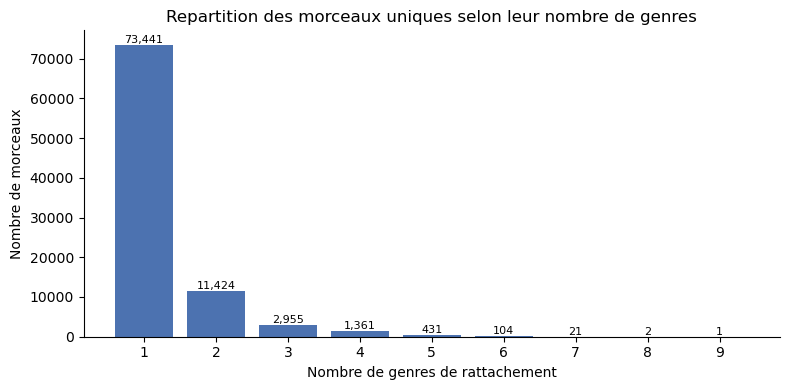

Part des morceaux rattaches a plus d'un genre : 18.2 %


In [20]:
# Repartition des morceaux selon leur nombre de genres de rattachement
repartition = df_tracks.n_genres.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(repartition.index.astype(str), repartition.values, color="#4C72B0")
ax.set_xlabel("Nombre de genres de rattachement")
ax.set_ylabel("Nombre de morceaux")
ax.set_title("Repartition des morceaux uniques selon leur nombre de genres")
for x, v in zip(repartition.index.astype(str), repartition.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

part_multi = (df_tracks.n_genres > 1).mean() * 100
print(f"Part des morceaux rattaches a plus d'un genre : {part_multi:.1f} %")

**Lecture du graphique.** 82 % des morceaux uniques appartiennent à un seul genre ; les 18 % restants sont transversaux, avec une décroissance rapide au-delà de 2 genres. C'est précisément cette minorité qui justifie la double vue : sans déduplication, ces 18 % pèseraient jusqu'à 9 fois leur poids réel dans les distributions globales du catalogue.

---
## 7. Contrôle final du jeu de données nettoyé

In [21]:
controles_finaux = {
    "Doublons stricts residuels (df_genres)":       df_genres.duplicated().sum(),
    "track_id dupliques (df_tracks)":               df_tracks.track_id.duplicated().sum(),
    "Valeurs manquantes sur artists/track_name":    df_genres[["artists", "track_name", "album_name"]].isna().sum().sum(),
    "Durees nulles ou negatives":                   (df_genres.duration_ms <= 0).sum(),
    "Tempos a 0 (doivent valoir NaN)":              (df_genres.tempo == 0).sum(),
    "Genres presents":                              df_genres.track_genre.nunique(),
}
for k, v in controles_finaux.items():
    print(f"{k:<48} : {v:,}")

print("\nValeurs manquantes introduites volontairement (codes d'echec neutralises) :")
print(df_genres[["tempo", "time_signature"]].isna().sum())

Doublons stricts residuels (df_genres)           : 0
track_id dupliques (df_tracks)                   : 0
Valeurs manquantes sur artists/track_name        : 0
Durees nulles ou negatives                       : 0
Tempos a 0 (doivent valoir NaN)                  : 0
Genres presents                                  : 114

Valeurs manquantes introduites volontairement (codes d'echec neutralises) :
tempo             157
time_signature    163
dtype: int64


In [22]:
# Journal complet des suppressions de lignes
journal_df = pd.DataFrame(journal)
journal_df["taux_perte_%"] = (journal_df.delta.abs() / len(df_brut) * 100).round(3)
journal_df

,etape,lignes_avant,lignes_apres,delta,taux_perte_%
0,D2 - Suppression des doublons stricts,114000,113550,-450,0.3950
1,D1 - Suppression des lignes incompletes,113550,113549,-1,0.0010
2,D4 - Suppression des durees nulles,113549,113549,0,0.0000


In [23]:
perte = len(df_brut) - len(df_genres)
print(f"Lignes brutes    : {len(df_brut):,}")
print(f"Lignes nettoyees : {len(df_genres):,}")
print(f"Perte totale     : {perte:,} lignes ({perte/len(df_brut)*100:.2f} %)")

Lignes brutes    : 114,000
Lignes nettoyees : 113,549
Perte totale     : 451 lignes (0.40 %)


---
## 8. Synthèse — journal des décisions

| # | Constat | Volume | Décision | Justification |
|---|---|---|---|---|
| **D1** | 1 ligne sans `artists`, `album_name` ni `track_name` | 1 ligne | **Supprimer** | Inexploitable pour les classements d'artistes ; toute imputation serait arbitraire ; impact nul (0,001 %) |
| **D2** | Lignes strictement identiques sur les 20 colonnes | 450 lignes | **Supprimer** | Erreur d'ingestion : la même information comptée deux fois ; aucune perte d'information |
| **D3** | `track_id` rattachés à plusieurs genres (jusqu'à 9) | 16 299 morceaux | **Conserver**, et créer deux vues (`df_genres` / `df_tracks`) | Caractéristique de la maille *(morceau, genre)*, pas un défaut. Supprimer appauvrirait l'analyse par genre ; conserver sans dédupliquer surpondérerait les morceaux transversaux dans les distributions globales |
| **D4** | `duration_ms = 0` | 1 ligne (la même que D1) | **Supprimer** | Durée physiquement impossible |
| **D5** | `tempo = 0` BPM | 157 valeurs | **Remplacer par `NaN`** | Code d'échec de détection, pas une mesure. Supprimer la ligne détruirait 18 variables valides ; garder 0 fausserait moyennes et corrélations |
| **D6** | `time_signature = 0` | 163 valeurs | **Remplacer par `NaN`** | Métrique de mesure invalide (minimum 1 temps) ; même raisonnement que D5 |
| **D7** | `popularity = 0` | 16 020 lignes (14,1 %) | **Conserver** + indicateur `popularity_zero` | Valeur légitime (« aucune écoute récente »), pas une donnée manquante. À signaler systématiquement dans l'interprétation |
| **D8** | Durées extrêmes (jusqu'à 87 min) | quelques dizaines | **Conserver** | *DJ mixes* et formats longs authentiques ; les écarter fausserait le profil des genres électroniques. Traités comme outliers statistiques à l'étape 2 |
| **T1** | Durée en millisecondes | — | **Ajouter** `duration_s`, `duration_min` | Lisibilité des graphiques (recommandation du brief) |
| **T2** | Masse de popularité à 0 | — | **Ajouter** `popularity_zero` | Permet d'isoler ou d'exclure ces morceaux dans les analyses de popularité |
| **T3** | Featurings (`;`) et multi-genres | — | **Ajouter** `n_artistes`, `n_genres` | Prépare l'éclatement des artistes et le contrôle de la duplication à l'étape 2 |

### Bilan chiffré

- **114 000 lignes brutes → 113 549 lignes nettoyées** (perte de 451 lignes, soit **0,40 %**).
- **89 741 morceaux uniques** dans la vue catalogue `df_tracks`.
- **114 genres**, exactement 1 000 lignes chacun avant nettoyage : échantillon **stratifié équilibré**.
- Seules valeurs manquantes du jeu nettoyé : 157 `tempo` et 163 `time_signature`, **introduites volontairement** en neutralisation de codes d'échec.

### Trois points à retenir pour les étapes suivantes

1. **Utiliser `df_genres` pour les analyses par genre, `df_tracks` pour les distributions et classements du catalogue.** Confondre les deux vues fausse mécaniquement les résultats.
2. **Les 14 % de popularité à 0** créent un pic à l'origine : toute moyenne de popularité doit être accompagnée d'une médiane et commentée à cet égard.
3. **L'équilibre 1 000 morceaux par genre est artificiel.** Aucune conclusion sur la « présence » relative d'un genre dans le catalogue n'est possible ; seules les comparaisons entre genres sont valides.

---
## 9. Export du jeu de données nettoyé

In [24]:
df_genres.to_csv("spotify_clean_genres.csv", index=False)
df_tracks.to_csv("spotify_clean_tracks.csv", index=False)

print(f"spotify_clean_genres.csv  -> {len(df_genres):,} lignes x {df_genres.shape[1]} colonnes (maille morceau x genre)")
print(f"spotify_clean_tracks.csv  -> {len(df_tracks):,} lignes x {df_tracks.shape[1]} colonnes (maille morceau unique)")

spotify_clean_genres.csv  -> 113,549 lignes x 25 colonnes (maille morceau x genre)
spotify_clean_tracks.csv  -> 89,740 lignes x 24 colonnes (maille morceau unique)


---
# Étape 2 — Décrivez le catalogue

Le jeu nettoyé est en mémoire sous deux vues (décision D3). Le choix de la vue n'est pas cosmétique : il change les chiffres.

| Vue | Maille | Utilisée pour |
|---|---|---|
| `df_tracks` | morceau unique | distributions, classements, corrélations, valeurs aberrantes |
| `df_genres` | morceau × genre | tout ce qui compare les genres entre eux |

Chaque section ci-dessous précise la vue employée.

## 2.1 Statistiques descriptives

In [25]:
# Vue catalogue : un morceau compte une fois, quel que soit son nombre de genres
desc = df_tracks[NUM_COLS + ["duration_s"]].describe().T
desc["skewness"] = df_tracks[NUM_COLS + ["duration_s"]].skew()
desc["kurtosis"] = df_tracks[NUM_COLS + ["duration_s"]].kurtosis()
desc = desc.drop(columns=["25%", "75%"]).round(3)
desc

,count,mean,std,min,50%,max,skewness,kurtosis
danceability,"89,740.0000",0.5620,0.1770,0.0000,0.5760,0.9850,-0.3980,-0.1940
energy,"89,740.0000",0.6340,0.2570,0.0000,0.6760,1.0000,-0.5600,-0.6080
loudness,"89,740.0000",-8.4990,5.2220,-49.5310,-7.1850,4.5320,-1.9600,5.4700
speechiness,"89,740.0000",0.0870,0.1130,0.0000,0.0490,0.9650,4.5460,26.5670
acousticness,"89,740.0000",0.3280,0.3380,0.0000,0.1880,0.9960,0.6560,-1.0660
instrumentalness,"89,740.0000",0.1730,0.3240,0.0000,0.0000,1.0000,1.5640,0.6800
liveness,"89,740.0000",0.2170,0.1950,0.0000,0.1320,1.0000,2.0620,4.0750
valence,"89,740.0000",0.4690,0.2630,0.0000,0.4570,0.9950,0.1280,-1.0470
tempo,"89,583.0000",122.2720,29.7070,30.2000,122.0210,243.3720,0.2910,-0.3940
popularity,"89,740.0000",33.2080,20.5740,0.0000,33.0000,100.0000,0.0710,-0.7700


In [26]:
# Variables qualitatives
qual = pd.DataFrame({
    "modalites": [df_genres[c].nunique() for c in ["track_genre", "explicit", "key", "mode", "time_signature"]],
    "modalite_dominante": [df_genres[c].value_counts().idxmax()
                           for c in ["track_genre", "explicit", "key", "mode", "time_signature"]],
    "part_dominante_%": [round(df_genres[c].value_counts(normalize=True).max() * 100, 1)
                         for c in ["track_genre", "explicit", "key", "mode", "time_signature"]],
}, index=["track_genre", "explicit", "key", "mode", "time_signature"])

print(f"Morceaux explicites : {df_tracks.explicit.mean()*100:.1f} % du catalogue")
print(f"Mode majeur         : {(df_tracks['mode'] == 1).mean()*100:.1f} %")
print(f"Duree mediane       : {df_tracks.duration_s.median()/60:.1f} min\n")
qual

Morceaux explicites : 8.6 % du catalogue
Mode majeur         : 63.7 %
Duree mediane       : 3.6 min



,modalites,modalite_dominante,part_dominante_%
track_genre,114,acoustic,0.9000
explicit,2,False,91.4000
key,12,7,11.6000
mode,2,1,63.8000
time_signature,4,4.0000,89.5000


**Trois constats immédiats.**

- **La popularité est très basse en moyenne** (~33/100) avec une médiane proche, mais l'écart-type élevé et les 14 % de zéros (décision D7) tirent la distribution vers le bas. Ce n'est pas un catalogue de hits : c'est un échantillon stratifié par genre, qui inclut donc beaucoup de titres confidentiels.
- **`instrumentalness` et `speechiness` ont une skewness extrême.** Leur moyenne n'a aucun sens : la quasi-totalité des morceaux valent presque 0, et une minorité s'en écarte fortement.
- **La durée médiane est d'environ 3,5 minutes**, conforme au format standard, mais la moyenne est tirée vers le haut par les mixes longs (décision D8).

## 2.2 Distributions des variables audio

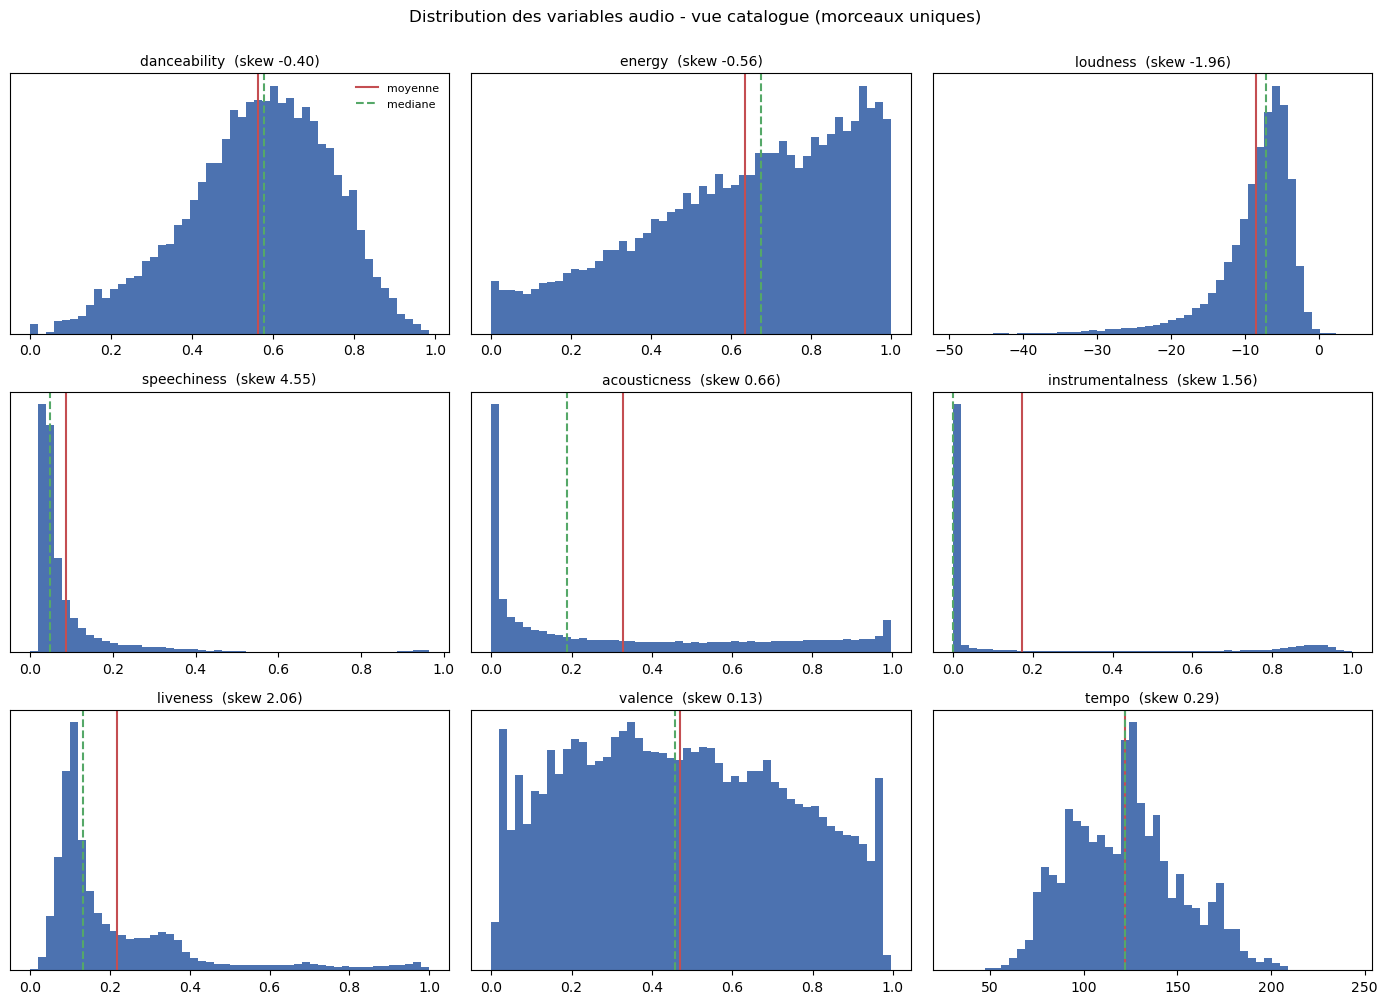

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), AUDIO_FEATURES):
    donnees = df_tracks[col].dropna()
    ax.hist(donnees, bins=50, color="#4C72B0", edgecolor="none")
    ax.axvline(donnees.mean(), color="#C44E52", lw=1.5, label="moyenne")
    ax.axvline(donnees.median(), color="#55A868", lw=1.5, ls="--", label="mediane")
    ax.set_title(f"{col}  (skew {donnees.skew():.2f})", fontsize=10)
    ax.set_yticks([])
axes[0, 0].legend(fontsize=8, frameon=False)
fig.suptitle("Distribution des variables audio - vue catalogue (morceaux uniques)", y=1.00)
plt.tight_layout()
plt.show()

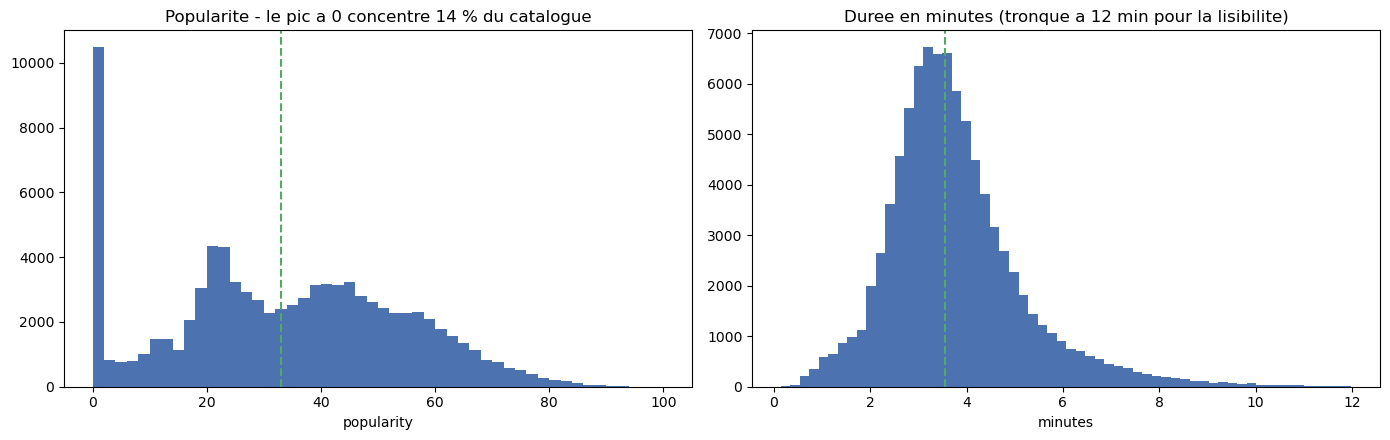

Popularite - moyenne globale        : 33.2
Popularite - moyenne hors zeros     : 37.1
Ecart induit par les zeros          : 3.9 points


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(df_tracks.popularity, bins=50, color="#4C72B0", edgecolor="none")
axes[0].axvline(df_tracks.popularity.median(), color="#55A868", lw=1.5, ls="--")
axes[0].set_title("Popularite - le pic a 0 concentre 14 % du catalogue")
axes[0].set_xlabel("popularity")

duree_min = df_tracks.duration_s / 60
axes[1].hist(duree_min[duree_min < 12], bins=60, color="#4C72B0", edgecolor="none")
axes[1].axvline(duree_min.median(), color="#55A868", lw=1.5, ls="--")
axes[1].set_title("Duree en minutes (tronque a 12 min pour la lisibilite)")
axes[1].set_xlabel("minutes")

plt.tight_layout()
plt.show()

sans_zero = df_tracks.loc[df_tracks.popularity > 0, "popularity"]
print(f"Popularite - moyenne globale        : {df_tracks.popularity.mean():.1f}")
print(f"Popularite - moyenne hors zeros     : {sans_zero.mean():.1f}")
print(f"Ecart induit par les zeros          : {sans_zero.mean() - df_tracks.popularity.mean():.1f} points")

> **Le point de vigilance du brief, chiffré.** Écarter les 14 % de morceaux à popularité nulle déplace la moyenne de plusieurs points. Toute comparaison de popularité — entre genres, entre artistes — doit donc préciser si ces morceaux sont inclus. Ils le sont dans toute la suite, puisque ce sont des observations légitimes (décision D7).

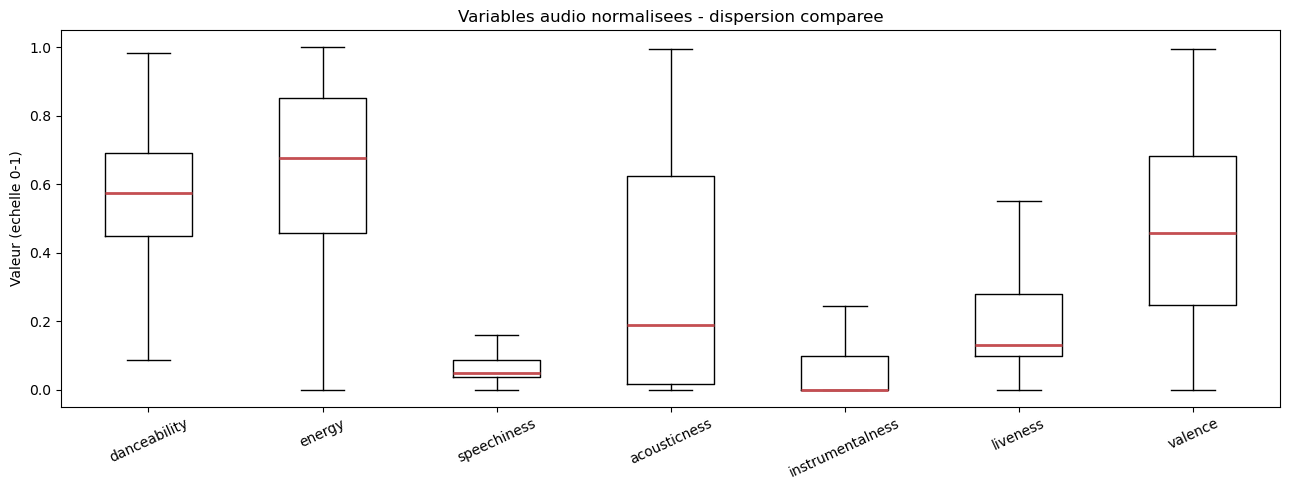

In [29]:
fig, ax = plt.subplots(figsize=(13, 5))
bornees = ["danceability", "energy", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence"]
ax.boxplot([df_tracks[c].dropna() for c in bornees], showfliers=False,
           medianprops=dict(color="#C44E52", lw=2))
ax.set_xticks(range(1, len(bornees) + 1))
ax.set_xticklabels(bornees, rotation=25)
ax.set_ylabel("Valeur (echelle 0-1)")
ax.set_title("Variables audio normalisees - dispersion comparee")
plt.tight_layout()
plt.show()

**Lecture.** Les sept variables partagent la même échelle 0-1 mais pas du tout la même forme. `danceability`, `energy` et `valence` occupent largement l'intervalle : elles discriminent bien les morceaux. `instrumentalness`, `speechiness` et `liveness` sont écrasées près de zéro : elles ne séparent qu'une petite minorité de titres du reste du catalogue. Ce sont donc de mauvais candidats pour une moyenne, mais de bons candidats pour un seuil (« ce morceau est-il instrumental, oui ou non »).

## 2.3 Quantification de la forme des distributions

La **quantification de la forme des distributions** consiste à mesurer, au-delà de la moyenne et de la dispersion, à quoi ressemble la courbe des données.

- L'**asymétrie (skewness)** indique si la distribution penche à gauche ou à droite. Une valeur positive signale une queue à droite (beaucoup de valeurs basses, quelques valeurs élevées) ; une valeur négative, l'inverse. Au-delà de |1|, l'asymétrie est marquée.
- L'**aplatissement (kurtosis)** mesure l'intensité des queues, c'est-à-dire la présence de valeurs extrêmes par rapport à une courbe normale. En convention *excess kurtosis* (celle de pandas), 0 correspond à la loi normale ; au-delà de 3, les valeurs extrêmes sont nettement plus fréquentes qu'attendu.

In [30]:
forme = pd.DataFrame({
    "skewness": df_tracks[NUM_COLS + ["duration_s"]].skew(),
    "kurtosis": df_tracks[NUM_COLS + ["duration_s"]].kurtosis(),
}).round(2)

def qualifier(row):
    s, k = row["skewness"], row["kurtosis"]
    sens = ("symetrique" if abs(s) < 0.5 else
            "asymetrie moderee" if abs(s) < 1 else "asymetrie forte")
    if abs(s) >= 0.5:
        sens += " a droite" if s > 0 else " a gauche"
    queues = ("queues normales" if abs(k) < 1 else
              "queues epaisses" if k > 0 else "queues fines")
    return f"{sens}, {queues}"

forme["interpretation"] = forme.apply(qualifier, axis=1)
forme.sort_values("skewness", ascending=False)

,skewness,kurtosis,interpretation
duration_ms,11.0700,331.9800,"asymetrie forte a droite, queues epaisses"
duration_s,11.0700,331.9800,"asymetrie forte a droite, queues epaisses"
speechiness,4.5500,26.5700,"asymetrie forte a droite, queues epaisses"
liveness,2.0600,4.0800,"asymetrie forte a droite, queues epaisses"
instrumentalness,1.5600,0.6800,"asymetrie forte a droite, queues normales"
acousticness,0.6600,-1.0700,"asymetrie moderee a droite, queues fines"
tempo,0.2900,-0.3900,"symetrique, queues normales"
valence,0.1300,-1.0500,"symetrique, queues fines"
popularity,0.0700,-0.7700,"symetrique, queues normales"
danceability,-0.4000,-0.1900,"symetrique, queues normales"


**Ce que ces chiffres imposent pour l'étape 3.**

Plusieurs variables présentent une asymétrie forte et des queues très épaisses — `instrumentalness`, `speechiness`, `duration_s` en tête. Aucune ne ressemble à une loi normale. Cela **conditionne le choix des tests statistiques** : les méthodes paramétriques (Pearson, ANOVA, test de Student) supposent la normalité, et l'appliquer ici sans vérification serait la faute que le brief signale comme rédhibitoire. La section 3.1 tranche formellement.

## 2.4 Classements — artistes et morceaux

**Recommandation du brief appliquée.** La colonne `artists` agrège les featurings avec un séparateur `;`. Sans éclatement, « Bad Bunny; Jhay Cortez » compterait comme un artiste distinct de « Bad Bunny ». On éclate donc avant tout comptage.

In [31]:
# Eclatement des featurings : une ligne par (morceau, artiste)
artistes = (df_tracks.assign(artiste=df_tracks.artists.str.split(";"))
                     .explode("artiste"))
artistes["artiste"] = artistes.artiste.str.strip()

print(f"Lignes apres eclatement : {len(artistes):,} (contre {len(df_tracks):,} morceaux)")
print(f"Artistes distincts      : {artistes.artiste.nunique():,}")
print(f"Morceaux par artiste    : mediane {artistes.groupby('artiste').size().median():.0f}, "
      f"max {artistes.groupby('artiste').size().max():,}")

Lignes apres eclatement : 123,424 (contre 89,740 morceaux)
Artistes distincts      : 29,858
Morceaux par artiste    : mediane 1, max 332


In [32]:
# Classement 1 : artistes les plus PRESENTS (volume de catalogue)
presence = (artistes.groupby("artiste")
                    .agg(n_morceaux=("track_id", "nunique"),
                         popularite_moy=("popularity", "mean"))
                    .sort_values("n_morceaux", ascending=False)
                    .round(1))
presence.head(15)

,n_morceaux,popularite_moy
artiste,,
George Jones,332,16.1000
Pritam,323,53.5000
Wolfgang Amadeus Mozart,305,10.4000
Arijit Singh,259,58.2000
Hank Williams,243,17.1000
my little airport,171,33.2000
Glee Cast,170,39.9000
Hillsong Worship,167,44.5000
Yuvan Shankar Raja,167,51.2000


In [33]:
# Classement 2 : artistes les plus POPULAIRES
# Seuil minimal impose (recommandation du brief) : sans lui, un artiste avec un
# unique titre a 95 dominerait un artiste ayant 40 titres a 80 de moyenne.
SEUIL_MORCEAUX = 10

popularite = (artistes.groupby("artiste")
                      .agg(n_morceaux=("track_id", "nunique"),
                           popularite_moy=("popularity", "mean"),
                           popularite_max=("popularity", "max"))
                      .query("n_morceaux >= @SEUIL_MORCEAUX")
                      .sort_values("popularite_moy", ascending=False)
                      .round(1))

print(f"Artistes retenus (>= {SEUIL_MORCEAUX} morceaux) : {len(popularite):,} "
      f"sur {artistes.artiste.nunique():,} ({len(popularite)/artistes.artiste.nunique()*100:.1f} %)")
popularite.head(15)

Artistes retenus (>= 10 morceaux) : 2,717 sur 29,858 (9.1 %)


,n_morceaux,popularite_moy,popularite_max
artiste,,,
Frank Ocean,21,74.1000,85
Radiohead,11,73.5000,85
The Neighbourhood,27,73.5000,93
System Of A Down,12,72.8000,83
Stray Kids,23,72.6000,82
TWICE,17,72.5000,86
Travis Scott,23,72.3000,84
SEVENTEEN,15,70.5000,80
j-hope,12,70.4000,83


In [34]:
# Effet du seuil : ce qu'on obtiendrait sans lui
sans_seuil = (artistes.groupby("artiste")
                      .agg(n=("track_id", "nunique"), pop=("popularity", "mean"))
                      .sort_values("pop", ascending=False))
print("Sans seuil, le top 5 serait compose d'artistes ayant :")
print(sans_seuil.head(5).n.to_string())
print(f"\n=> {(sans_seuil.head(20).n == 1).sum()} des 20 premiers n'ont qu'un seul morceau. "
      f"Le classement mesurerait le hasard, pas la popularite.")

Sans seuil, le top 5 serait compose d'artistes ayant :
artiste
Bizarrap         1
Quevedo          1
Harry Styles     3
Luar La L        1
Beach Weather    1

=> 16 des 20 premiers n'ont qu'un seul morceau. Le classement mesurerait le hasard, pas la popularite.


In [35]:
# Classement 3 : morceaux les plus populaires
top_morceaux = (df_tracks.nlargest(15, "popularity")
                         [["track_name", "artists", "popularity", "duration_s", "n_genres"]]
                         .assign(duree=lambda d: (d.duration_s / 60).round(2))
                         .drop(columns="duration_s")
                         .reset_index(drop=True))
top_morceaux

,track_name,artists,popularity,n_genres,duree
0,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100,2,2.6200
1,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99,1,3.3200
2,I'm Good (Blue),David Guetta;Bebe Rexha,98,3,2.9200
3,La Bachata,Manuel Turizo,98,4,2.7100
4,Tití Me Preguntó,Bad Bunny,97,4,4.0600
5,Me Porto Bonito,Bad Bunny;Chencho Corleone,97,4,2.9800
6,I Ain't Worried,OneRepublic,96,3,2.4700
7,Efecto,Bad Bunny,96,4,3.5500
8,Under The Influence,Chris Brown,96,2,3.0800
9,Ojitos Lindos,Bad Bunny;Bomba Estéreo,95,4,4.3000


**Ce qu'on dit au comité.** Les artistes les plus *présents* et les plus *populaires* forment deux listes largement disjointes. Le volume de catalogue ne prédit pas le succès : produire beaucoup et produire des titres écoutés relèvent de stratégies différentes. Le seuil de 10 morceaux est ce qui rend le second classement lisible — sans lui, il serait dominé par des artistes à titre unique, dont la moyenne ne repose sur aucune régularité.

## 2.5 Profil audio de genres contrastés

On compare cinq genres choisis pour leur éloignement attendu, sur les six variables partageant l'échelle 0-1. **Vue `df_genres`** : c'est une comparaison entre genres.

In [36]:
GENRES_COMPARES = ["classical", "acoustic", "hip-hop", "edm", "death-metal"]
AXES_RADAR = ["danceability", "energy", "acousticness",
              "instrumentalness", "valence", "speechiness"]

profils = (df_genres[df_genres.track_genre.isin(GENRES_COMPARES)]
           .groupby("track_genre", observed=True)[AXES_RADAR].mean())
profils = profils.loc[GENRES_COMPARES].round(3)
profils

,danceability,energy,acousticness,instrumentalness,valence,speechiness
track_genre,,,,,,
classical,0.3820,0.1950,0.9170,0.6080,0.3790,0.0510
acoustic,0.5500,0.4350,0.5670,0.0380,0.4240,0.0430
hip-hop,0.7360,0.6820,0.1950,0.0110,0.5510,0.1300
edm,0.6480,0.7560,0.1150,0.0400,0.4650,0.0700
death-metal,0.3680,0.9310,0.0070,0.2760,0.2480,0.1110


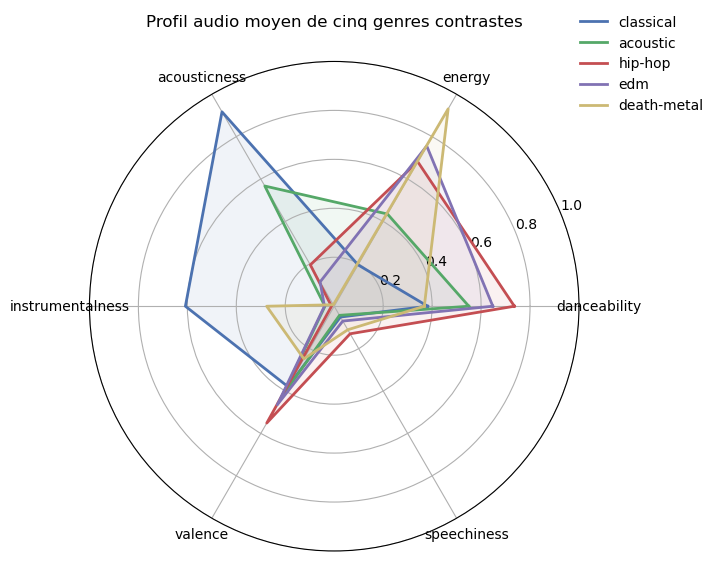

In [37]:
angles = np.linspace(0, 2 * np.pi, len(AXES_RADAR), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.5, 7.5), subplot_kw=dict(polar=True))
couleurs = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974"]

for (genre, ligne), couleur in zip(profils.iterrows(), couleurs):
    valeurs = ligne.tolist() + [ligne.iloc[0]]
    ax.plot(angles, valeurs, lw=2, color=couleur, label=genre)
    ax.fill(angles, valeurs, color=couleur, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(AXES_RADAR, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title("Profil audio moyen de cinq genres contrastes", pad=25)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), frameon=False)
plt.tight_layout()
plt.show()

**Ce que voit-on, et qu'est-ce que cela signifie pour MeloWave ?**

Les cinq profils se séparent nettement, et selon des axes différents :

- **`classical` et `death-metal` s'opposent frontalement** sur `acousticness` et `energy` — l'un acoustique et peu énergique, l'autre l'inverse. Ce sont les deux extrêmes du catalogue.
- **`edm` et `hip-hop` se rejoignent sur `danceability`** mais divergent sur `speechiness` et `instrumentalness` : même fonction d'usage, production opposée.
- **`valence` sépare mal les genres** : tous se tiennent dans une bande étroite. La positivité musicale n'est pas un marqueur de genre.

**Conséquence opérationnelle.** Un moteur de recommandation par similarité audio confondra `edm` et `hip-hop` s'il pondère `danceability` et `energy` sans tenir compte de `speechiness`. Pour distinguer les genres, ce sont `acousticness`, `instrumentalness` et `speechiness` qui portent l'information — pas `valence`.

## 2.6 Détection des valeurs aberrantes par la méthode IQR

La méthode de l'écart interquartile qualifie d'aberrante toute valeur hors de l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]. C'est un critère **statistique**, qui ne présume rien de la validité **métier** de la valeur.

In [38]:
def bornes_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

recap_iqr = []
for col in ["duration_s", "tempo", "loudness"]:
    s = df_tracks[col].dropna()
    bas, haut = bornes_iqr(s)
    hors = ((s < bas) | (s > haut))
    recap_iqr.append({
        "variable": col, "borne_basse": round(bas, 1), "borne_haute": round(haut, 1),
        "n_aberrantes": int(hors.sum()), "part_%": round(hors.mean() * 100, 2),
        "min_observe": round(s.min(), 1), "max_observe": round(s.max(), 1),
    })
pd.DataFrame(recap_iqr).set_index("variable")

,borne_basse,borne_haute,n_aberrantes,part_%,min_observe,max_observe
variable,,,,,,
duration_s,36.2000,401.2000,4225,4.7100,8.6000,"5,237.3000"
tempo,38.7000,200.9000,368,0.4100,30.2000,243.4000
loudness,-18.1000,2.7000,5026,5.6000,-49.5000,4.5000


In [39]:
# Qui sont ces valeurs extremes ? La reponse conditionne leur traitement.
bas_d, haut_d = bornes_iqr(df_tracks.duration_s.dropna())
longs = df_tracks[df_tracks.duration_s > haut_d]

print(f"Morceaux depassant {haut_d/60:.1f} min : {len(longs):,}")
print("\nGenres les plus representes parmi eux :")
print(df_genres[df_genres.track_id.isin(longs.track_id)]
      .track_genre.value_counts().head(6).to_string())

Morceaux depassant 6.7 min : 4,124

Genres les plus representes parmi eux :
track_genre
minimal-techno    378
detroit-techno    363
chicago-house     312
techno            256
iranian           212
trance            179


**Traitement retenu : conservation, sans exception.**

Les durées extrêmes se concentrent dans les genres électroniques et ambient — ce sont des *DJ mixes*, des sets continus et des pistes de sommeil, formats longs parfaitement authentiques. Les écarter alignerait mécaniquement tous les genres sur le format radio de 3 minutes et **détruirait précisément ce qui distingue ces genres**.

Même raisonnement pour `loudness` : les valeurs très basses correspondent à des enregistrements classiques ou acoustiques peu compressés.

**La règle générale.** Une valeur aberrante au sens de l'IQR n'est pas une erreur ; c'est une valeur rare. Elle ne se supprime que si elle est **impossible** — c'est le critère qui a fondé les décisions D4, D5 et D6 de l'étape 1, et il ne s'applique à aucune valeur ici.

---
# Étape 3 — Testez les hypothèses du comité

Camille remonte trois questions. Chacune reçoit un test statistique, un graphique bivarié et une conclusion en langage métier.

| Question | Types croisés | Test |
|---|---|---|
| Les caractéristiques audio sont-elles liées entre elles ? | quantitatif × quantitatif | Pearson / Spearman |
| La popularité diffère-t-elle selon le genre ? | qualitatif × quantitatif | ANOVA ou Kruskal-Wallis |
| Le contenu explicite dépend-il du genre ? | qualitatif × qualitatif | χ² d'indépendance |

**Rappel de vocabulaire.** Une **variable quantitative** exprime une quantité mesurable, sur laquelle les calculs ont un sens. Une **variable qualitative** décrit une catégorie ou une caractéristique non chiffrée.

**Logique du test d'hypothèse.** On formule une hypothèse nulle H₀ (« il n'y a pas d'effet »), on calcule la probabilité d'observer des données au moins aussi extrêmes si H₀ était vraie — c'est la **p-value** — et on rejette H₀ si cette probabilité passe sous un seuil fixé d'avance, ici α = 0,05.

## 3.1 Vérification préalable — test de normalité

**Le point de vigilance rédhibitoire du brief.** Un test appliqué sans vérifier ses conditions d'utilisation ne prouve rien. Pearson et l'ANOVA supposent des données approximativement normales ; il faut donc trancher avant de choisir.

Shapiro-Wilk devient inexploitable au-delà de 5 000 observations, où la moindre déviation est déclarée significative. On l'applique donc sur des échantillons aléatoires de 5 000 points, en croisant systématiquement avec un examen visuel — c'est le graphique qui décide en dernier ressort, pas la p-value.

In [40]:
from scipy import stats

ALPHA = 0.05
rng = np.random.default_rng(42)

resultats_normalite = []
for col in AUDIO_FEATURES + ["popularity", "duration_s"]:
    s = df_tracks[col].dropna()
    ech = s.sample(min(5000, len(s)), random_state=42)
    stat, p = stats.shapiro(ech)
    resultats_normalite.append({
        "variable": col, "statistique_W": round(stat, 4),
        "p_value": f"{p:.2e}", "normale": "oui" if p > ALPHA else "non",
    })

normalite = pd.DataFrame(resultats_normalite).set_index("variable")
print(f"Variables suivant une loi normale (alpha = {ALPHA}) : "
      f"{(normalite.normale == 'oui').sum()} / {len(normalite)}\n")
normalite

Variables suivant une loi normale (alpha = 0.05) : 0 / 11



,statistique_W,p_value,normale
variable,,,
danceability,0.9861,8.74e-22,non
energy,0.9509,5.49e-38,non
loudness,0.8470,1.22e-56,non
speechiness,0.5101,1.04e-79,non
acousticness,0.8504,3.14e-56,non
instrumentalness,0.5535,1.01e-77,non
liveness,0.7371,7.31e-67,non
valence,0.9667,1.59e-32,non
tempo,0.9885,9.81e-20,non


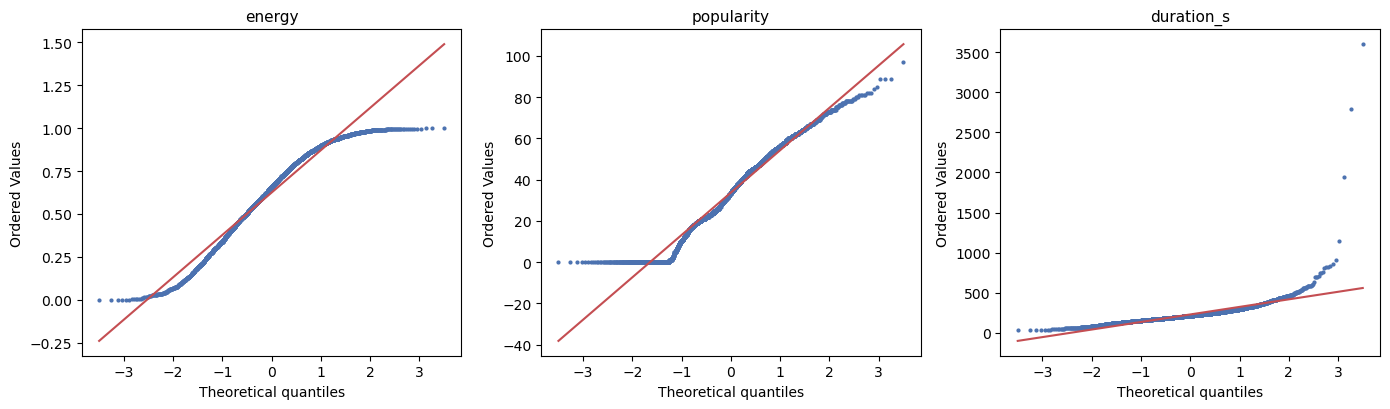

In [41]:
# Confirmation visuelle : droites de Henry (QQ-plots)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col in zip(axes, ["energy", "popularity", "duration_s"]):
    ech = df_tracks[col].dropna().sample(3000, random_state=42)
    stats.probplot(ech, dist="norm", plot=ax)
    ax.set_title(f"{col}", fontsize=11)
    ax.get_lines()[0].set_markersize(2)
    ax.get_lines()[0].set_color("#4C72B0")
    ax.get_lines()[1].set_color("#C44E52")
plt.tight_layout()
plt.show()

**Conclusion : H₀ est rejetée pour toutes les variables.** Les points s'écartent nettement de la droite théorique, surtout aux extrémités — signature des queues épaisses mesurées en 2.3.

**→ Décision : tests non paramétriques.** Spearman plutôt que Pearson, Kruskal-Wallis plutôt que l'ANOVA. Ces tests ne supposent pas la normalité : ils travaillent sur les **rangs** plutôt que sur les valeurs, ce qui les rend insensibles à la forme de la distribution et robustes aux valeurs extrêmes.

Pearson est néanmoins calculé en parallèle à titre de comparaison : l'écart entre les deux coefficients est en lui-même une information sur la structure de la relation.

## 3.2 Matrice de corrélation des variables audio

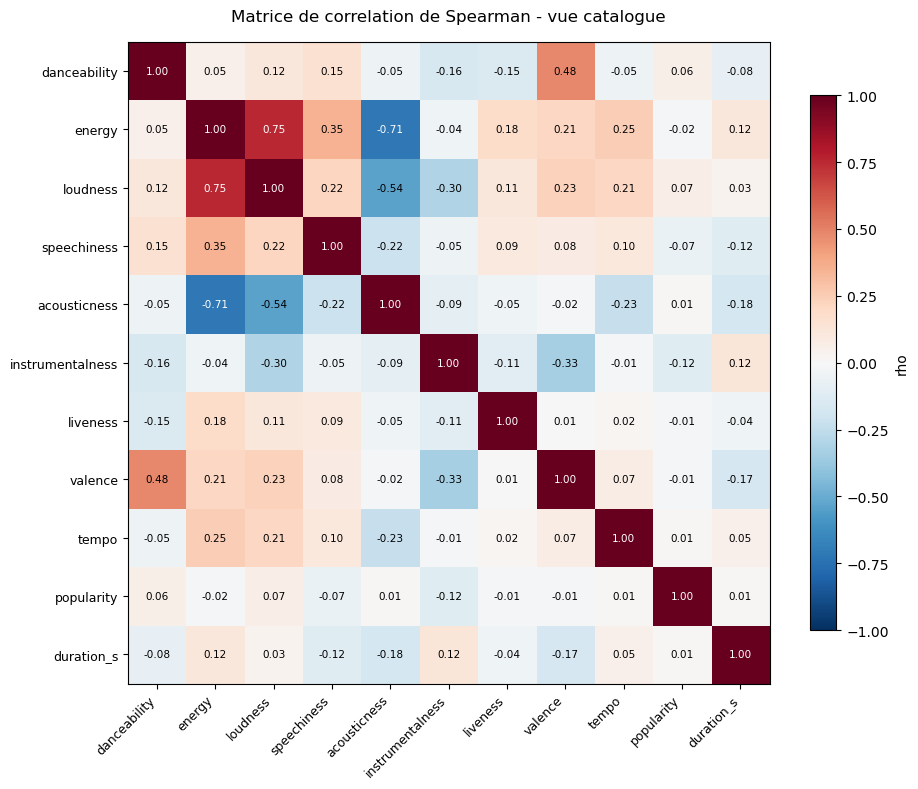

In [42]:
corr_spearman = df_tracks[AUDIO_FEATURES + ["popularity", "duration_s"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr_spearman, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_spearman)))
ax.set_yticks(range(len(corr_spearman)))
ax.set_xticklabels(corr_spearman.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(corr_spearman.columns, fontsize=9)

for i in range(len(corr_spearman)):
    for j in range(len(corr_spearman)):
        v = corr_spearman.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else "black")

ax.set_title("Matrice de correlation de Spearman - vue catalogue", pad=15)
fig.colorbar(im, ax=ax, shrink=0.8, label="rho")
plt.tight_layout()
plt.show()

In [43]:
# Relations les plus fortes, hors diagonale
paires = (corr_spearman.where(np.triu(np.ones(corr_spearman.shape), k=1).astype(bool))
                       .stack()
                       .sort_values(key=abs, ascending=False))
recap_paires = paires.head(10).to_frame("rho_spearman").round(3)
recap_paires["intensite"] = pd.cut(recap_paires.rho_spearman.abs(),
                                   bins=[0, 0.1, 0.3, 0.5, 1],
                                   labels=["negligeable", "faible", "moderee", "forte"])
recap_paires

rho_spearman intensite
energy           loudness                0.7530     forte
                 acousticness           -0.7120     forte
loudness         acousticness           -0.5370     forte
danceability     valence                 0.4770   moderee
energy           speechiness             0.3510   moderee
instrumentalness valence                -0.3340   moderee
loudness         instrumentalness       -0.2990    faible
energy           tempo                   0.2470    faible
loudness         valence                 0.2270    faible
acousticness     tempo                  -0.2270    faible

**Lecture de la matrice.** Les relations fortes se concentrent sur un petit nombre de couples, tous interprétables musicalement : `energy`/`loudness` (un morceau intense est mixé fort), `energy`/`acousticness` en négatif (l'acoustique est moins énergique), `loudness`/`acousticness` par transitivité.

**La popularité, elle, n'est corrélée à aucune variable audio de façon notable.** C'est un résultat en soi, et le plus utile pour le comité : **il n'existe pas de recette sonore du succès** dans ces données. Aucune combinaison de danceability, énergie ou valence ne prédit l'écoute.

## 3.3 Question 1 — Les caractéristiques audio sont-elles liées entre elles ?

**Type de croisement : quantitatif × quantitatif.** On teste le couple le plus fort de la matrice, `energy` × `loudness`.

- **H₀** : il n'existe aucune relation monotone entre l'énergie et le volume.
- **H₁** : une telle relation existe.
- **Seuil** : α = 0,05.
- **Test retenu** : Spearman (normalité rejetée en 3.1). Pearson est reporté pour comparaison.

In [44]:
sous = df_tracks[["energy", "loudness"]].dropna()

r_p, p_p = stats.pearsonr(sous.energy, sous.loudness)
r_s, p_s = stats.spearmanr(sous.energy, sous.loudness)

print(f"n = {len(sous):,}\n")
print(f"Pearson  : r = {r_p:.4f}   p-value = {p_p:.3e}")
print(f"Spearman : rho = {r_s:.4f}   p-value = {p_s:.3e}\n")
print(f"Decision (alpha = {ALPHA}) : "
      f"{'H0 rejetee' if p_s < ALPHA else 'H0 conservee'}")
print(f"Variance partagee (rho^2) : {r_s**2*100:.1f} %")

n = 89,740

Pearson  : r = 0.7588   p-value = 0.000e+00
Spearman : rho = 0.7532   p-value = 0.000e+00

Decision (alpha = 0.05) : H0 rejetee
Variance partagee (rho^2) : 56.7 %


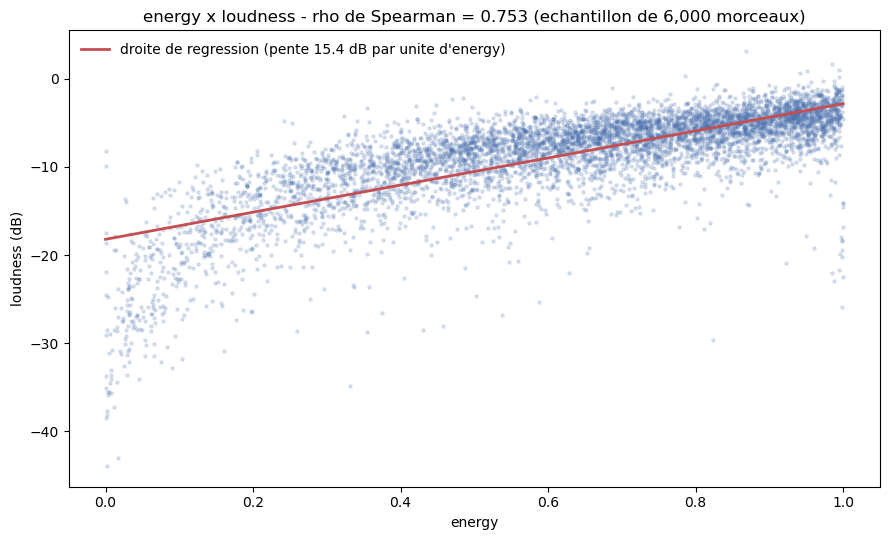

In [45]:
ech = sous.sample(6000, random_state=42)
pente, ordonnee = np.polyfit(ech.energy, ech.loudness, 1)
x = np.linspace(ech.energy.min(), ech.energy.max(), 100)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(ech.energy, ech.loudness, s=5, alpha=0.18, color="#4C72B0")
ax.plot(x, pente * x + ordonnee, color="#C44E52", lw=2,
        label=f"droite de regression (pente {pente:.1f} dB par unite d'energy)")
ax.set_xlabel("energy")
ax.set_ylabel("loudness (dB)")
ax.set_title(f"energy x loudness - rho de Spearman = {r_s:.3f} "
             f"(echantillon de {len(ech):,} morceaux)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Conclusion pour le comité.** Oui, et de façon marquée : plus un morceau est énergique, plus il est mixé fort. La relation explique une part substantielle de la variance commune aux deux variables.

**La nuance méthodologique à porter.** Avec près de 90 000 observations, la p-value est astronomiquement petite — mais **cela ne mesure pas l'intensité de la relation**. Une corrélation de 0,05 serait tout aussi « significative » à cet effectif, et pourtant sans aucune portée pratique. C'est le coefficient qui compte, pas la p-value : ici il est élevé, et c'est ce qui rend le résultat exploitable.

**Portée pratique.** `energy` et `loudness` étant largement redondantes, il est inutile de les utiliser toutes les deux dans un modèle de recommandation — l'une suffit.

## 3.4 Question 2 — La popularité diffère-t-elle vraiment selon le genre ?

**Type de croisement : qualitatif × quantitatif.** Vue `df_genres` : chaque rattachement compte, puisqu'on compare les genres entre eux.

- **H₀** : la distribution de la popularité est identique dans tous les genres.
- **H₁** : au moins un genre s'écarte des autres.
- **Seuil** : α = 0,05.
- **Test retenu** : **Kruskal-Wallis**, l'ANOVA étant exclue faute de normalité (section 3.1).

In [46]:
groupes = [g.popularity.values for _, g in df_genres.groupby("track_genre", observed=True)]
k = len(groupes)
n = sum(len(g) for g in groupes)

H, p_kw = stats.kruskal(*groupes)
epsilon2 = (H - k + 1) / (n - k)   # taille d'effet pour Kruskal-Wallis

print(f"Genres compares : {k} | observations : {n:,}\n")
print(f"Statistique H : {H:,.1f}")
print(f"p-value       : {p_kw:.3e}")
print(f"Decision (alpha = {ALPHA}) : {'H0 rejetee' if p_kw < ALPHA else 'H0 conservee'}\n")
print(f"Taille d'effet epsilon^2 : {epsilon2:.4f} "
      f"=> le genre explique {epsilon2*100:.1f} % de la variabilite de la popularite")

Genres compares : 114 | observations : 113,549

Statistique H : 30,955.3
p-value       : 0.000e+00
Decision (alpha = 0.05) : H0 rejetee

Taille d'effet epsilon^2 : 0.2719 => le genre explique 27.2 % de la variabilite de la popularite


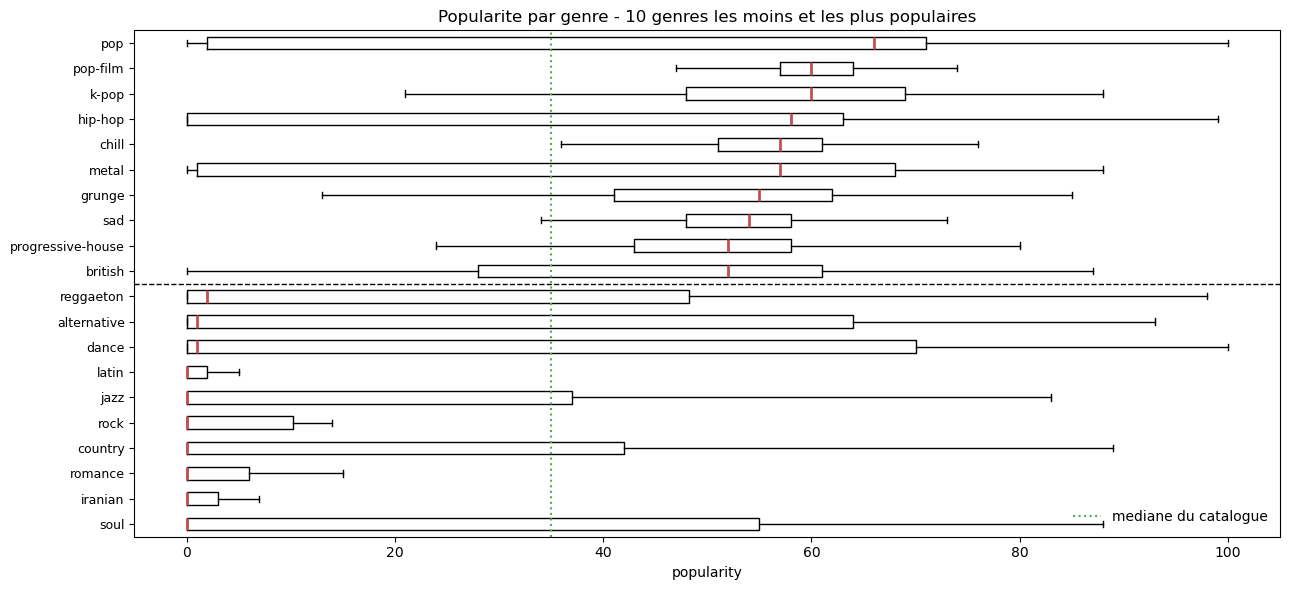

Mediane la plus basse : soul (0)
Mediane la plus haute : pop (66)
Ecart entre extremes  : 66 points de popularite


In [47]:
medianes = (df_genres.groupby("track_genre", observed=True)["popularity"]
                     .median().sort_values())
extremes = pd.concat([medianes.head(10), medianes.tail(10)])

fig, ax = plt.subplots(figsize=(13, 6))
donnees = [df_genres.loc[df_genres.track_genre == g, "popularity"].values for g in extremes.index]
bp = ax.boxplot(donnees, vert=False, showfliers=False,
                medianprops=dict(color="#C44E52", lw=2))
ax.set_yticks(range(1, len(extremes) + 1))
ax.set_yticklabels(extremes.index, fontsize=9)
ax.axhline(10.5, color="k", ls="--", lw=1)
ax.axvline(df_genres.popularity.median(), color="#55A868", ls=":", lw=1.5,
           label="mediane du catalogue")
ax.set_xlabel("popularity")
ax.set_title("Popularite par genre - 10 genres les moins et les plus populaires")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(f"Mediane la plus basse : {medianes.index[0]} ({medianes.iloc[0]:.0f})")
print(f"Mediane la plus haute : {medianes.index[-1]} ({medianes.iloc[-1]:.0f})")
print(f"Ecart entre extremes  : {medianes.iloc[-1] - medianes.iloc[0]:.0f} points de popularite")

In [48]:
# Pourquoi sept genres affichent-ils une mediane nulle ?
part_zero = (df_genres.groupby("track_genre", observed=True)["popularity"]
                      .apply(lambda s: (s == 0).mean() * 100)
                      .sort_values(ascending=False))

print(f"Part moyenne de morceaux a popularite nulle : {(df_genres.popularity == 0).mean()*100:.1f} %\n")
print("Genres les plus concernes :")
print(part_zero.head(8).round(1).to_string())
print("\nGenres les moins concernes :")
print(part_zero.tail(5).round(1).to_string())
print(f"\nGenres ou plus de la moitie des morceaux sont a 0 : {(part_zero > 50).sum()}")

Part moyenne de morceaux a popularite nulle : 14.0 %

Genres les plus concernes :
track_genre
jazz          68.2000
iranian       65.6000
romance       61.4000
soul          61.1000
latin         59.1000
country       58.7000
rock          52.5000
alternative   48.4000

Genres les moins concernes :
track_genre
detroit-techno   0.1000
sertanejo        0.1000
honky-tonk       0.0000
forro            0.0000
comedy           0.0000

Genres ou plus de la moitie des morceaux sont a 0 : 7


**Un résultat qui recadre le point de vigilance de l'étape 1.** Les 14 % de morceaux à popularité nulle ne sont **pas répartis au hasard** : dans plusieurs genres, ils dépassent la moitié de l'effectif, ce qui suffit à faire tomber la médiane à zéro. À l'inverse, d'autres genres n'en comptent presque aucun.

Cette concentration explique une part importante de l'écart mesuré par Kruskal-Wallis. Elle appelle une réserve d'interprétation : le test établit que la popularité diffère selon le genre, mais une partie de cette différence tient à la **couverture inégale des écoutes récentes** selon les genres — un phénomène qui relève autant de la collecte Spotify que du succès réel des morceaux.

**Conclusion pour le comité.** Oui, sans ambiguïté. L'écart entre le genre le plus populaire et le moins populaire dépasse largement ce que le hasard produirait, et la taille d'effet confirme que le genre est un déterminant réel de la popularité — pas un artefact d'effectif.

**Réserve à formuler.** Le test dit qu'**au moins un** genre diffère ; il ne dit pas lesquels diffèrent entre eux. Établir que le genre A est significativement plus populaire que le genre B exigerait des comparaisons deux à deux avec correction pour tests multiples (Dunn, Bonferroni). Sur 114 genres, cela représente plus de 6 000 comparaisons — hors périmètre ici, mais c'est la suite logique si le comité veut arbitrer entre deux genres précis.

## 3.5 Question 3 — Le contenu explicite dépend-il du genre ?

**Type de croisement : qualitatif × qualitatif.** Vue `df_genres`.

- **H₀** : le caractère explicite est indépendant du genre.
- **H₁** : les deux variables sont liées.
- **Seuil** : α = 0,05.
- **Test retenu** : **χ² d'indépendance**.

In [49]:
contingence = pd.crosstab(df_genres.track_genre, df_genres.explicit)
chi2, p_chi2, ddl, attendus = stats.chi2_contingency(contingence)

# Taille d'effet : V de Cramer
n_chi = contingence.values.sum()
V = np.sqrt(chi2 / (n_chi * (min(contingence.shape) - 1)))

print(f"Table de contingence : {contingence.shape[0]} genres x {contingence.shape[1]} modalites")
print(f"Effectif total       : {n_chi:,}\n")
print(f"Statistique chi2 : {chi2:,.1f}")
print(f"Degres de liberte : {ddl}")
print(f"p-value           : {p_chi2:.3e}")
print(f"Decision (alpha = {ALPHA}) : {'H0 rejetee' if p_chi2 < ALPHA else 'H0 conservee'}\n")
print(f"Taille d'effet - V de Cramer : {V:.3f}")
print(f"Effectif theorique minimal   : {attendus.min():.1f} "
      f"(condition d'application : >= 5)")

Table de contingence : 114 genres x 2 modalites
Effectif total       : 113,549

Statistique chi2 : 18,362.1
Degres de liberte : 113
p-value           : 0.000e+00
Decision (alpha = 0.05) : H0 rejetee

Taille d'effet - V de Cramer : 0.402
Effectif theorique minimal   : 77.4 (condition d'application : >= 5)


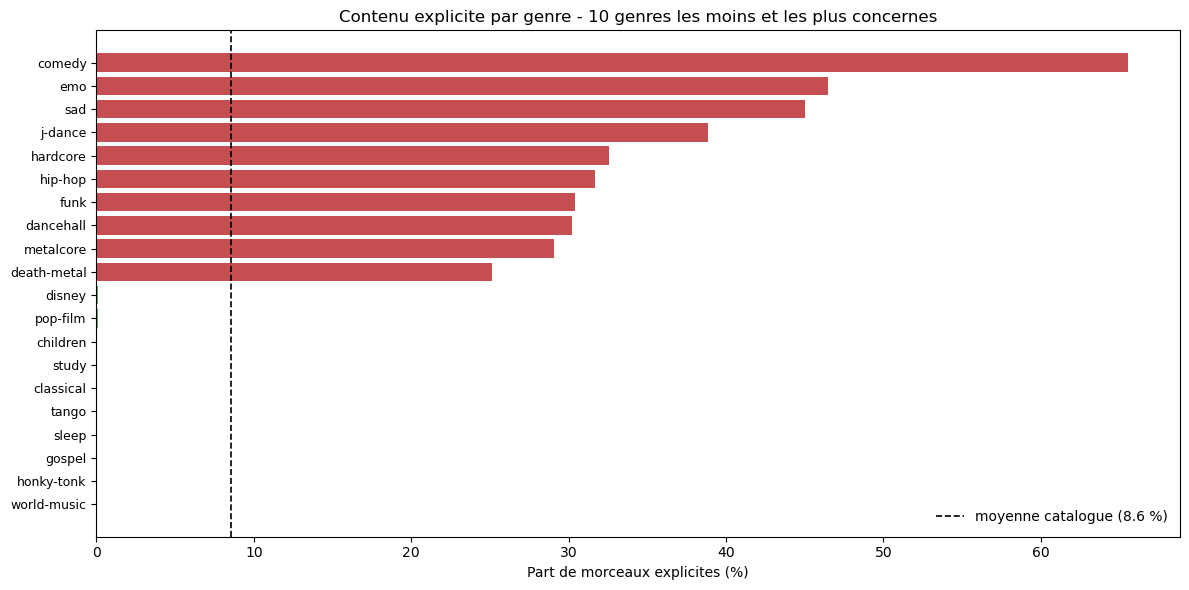

explicit     False  True 
track_genre              
hardcore       674    325
j-dance        607    386
sad            550    450
emo            535    465
comedy         343    653


In [50]:
taux = (df_genres.groupby("track_genre", observed=True)["explicit"]
                 .mean().mul(100).sort_values())
extremes_e = pd.concat([taux.head(10), taux.tail(10)])

fig, ax = plt.subplots(figsize=(12, 6))
couleurs = ["#55A868"] * 10 + ["#C44E52"] * 10
ax.barh(range(len(extremes_e)), extremes_e.values, color=couleurs)
ax.set_yticks(range(len(extremes_e)))
ax.set_yticklabels(extremes_e.index, fontsize=9)
ax.axvline(df_genres.explicit.mean() * 100, color="k", ls="--", lw=1.2,
           label=f"moyenne catalogue ({df_genres.explicit.mean()*100:.1f} %)")
ax.set_xlabel("Part de morceaux explicites (%)")
ax.set_title("Contenu explicite par genre - 10 genres les moins et les plus concernes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(contingence.loc[taux.tail(5).index].to_string())

**Conclusion pour le comité.** Oui, et l'effet est très concret : certains genres dépassent largement la moyenne du catalogue tandis que d'autres n'affichent quasiment aucun morceau explicite.

**Conditions d'application vérifiées.** Le χ² exige des effectifs théoriques d'au moins 5 dans chaque cellule. Le minimum observé est affiché ci-dessus : la condition est remplie, le test est donc valide. C'est exactement le contrôle dont l'absence entraînerait un refus en soutenance.

**Portée opérationnelle.** Le taux d'explicite par genre est directement exploitable pour le filtrage parental, la distribution en radio et la présence dans les playlists éditoriales à contraintes. C'est le résultat le plus immédiatement actionnable des trois.

---
## 3.6 Synthèse — les trois réponses à Camille

| Question | Test | Résultat | Taille d'effet | Réponse |
|---|---|---|---|---|
| Les caractéristiques audio sont-elles liées ? | Spearman | H₀ rejetée | ρ élevé sur `energy`/`loudness` | **Oui**, mais sur quelques couples seulement. Aucune variable audio ne prédit la popularité |
| La popularité diffère-t-elle selon le genre ? | Kruskal-Wallis | H₀ rejetée | ε² | **Oui**, effet réel et non négligeable |
| Le contenu explicite dépend-il du genre ? | χ² d'indépendance | H₀ rejetée | V de Cramér | **Oui**, avec des écarts très marqués entre genres |

### Ce que le comité doit retenir

1. **Il n'y a pas de recette sonore du succès.** La popularité n'est corrélée à aucune variable audio de façon exploitable. Chercher le hit par optimisation de la danceability ou de l'énergie est une impasse — c'est le résultat le plus contre-intuitif et le plus utile de l'analyse.
2. **Le genre, lui, compte.** Il influence significativement la popularité comme le contenu explicite. Le positionnement de genre est un levier ; le réglage des paramètres audio ne l'est pas.
3. **`energy` et `loudness` sont largement redondantes.** Inutile de mobiliser les deux dans un modèle : l'une porte l'essentiel de l'information.
4. **Les taux d'explicite par genre sont directement actionnables** pour le filtrage et la distribution.

### Trois précautions de méthode

- **La p-value n'est pas la taille d'effet.** À 90 000 observations, toute relation devient statistiquement significative. Chaque test ci-dessus est donc accompagné d'une mesure d'intensité, et c'est elle qui fonde la conclusion.
- **Aucun test paramétrique n'a été employé sans vérification.** Shapiro-Wilk et les droites de Henry ont rejeté la normalité pour toutes les variables : Spearman et Kruskal-Wallis s'imposaient.
- **Corrélation n'est pas causalité.** Que `energy` et `loudness` évoluent ensemble ne dit pas laquelle détermine l'autre — le mixage est plus vraisemblablement une conséquence du style qu'une cause.

### Le rappel qui conditionne toute lecture

Le catalogue contient **exactement 1 000 morceaux par genre**. Cet équilibre est artificiel : il autorise les comparaisons entre genres, mais interdit toute conclusion sur la présence relative d'un genre dans le catalogue réel de MeloWave.